In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import networkx as nx
import csv
import seaborn as sns
import pickle


In [5]:
#reading graph
if not os.path.isfile('train_woheader.csv'):
    traincsv = pd.read_csv('train.csv')
    print(traincsv[traincsv.isna().any(axis=1)])
    print(traincsv.info())
    print("Number of duplicate entries: ",sum(traincsv.duplicated()))
    traincsv.to_csv('train_woheader.csv',header=False,index=False)
    print("saved the graph into file")
else:
    g=nx.read_edgelist('train_woheader.csv',delimiter=',',create_using=nx.DiGraph(),nodetype=int)
    print(f"Graph Info:")
    print(f"Number of nodes: {g.number_of_nodes()}")
    print(f"Number of edges: {g.number_of_edges()}")
    print(f"Graph type: {type(g)}")

Graph Info:
Number of nodes: 1862220
Number of edges: 9437519
Graph type: <class 'networkx.classes.digraph.DiGraph'>


> Displaying a sub graph

Graph Info:
Number of nodes: 66
Number of edges: 50
Graph type: <class 'networkx.classes.digraph.DiGraph'>


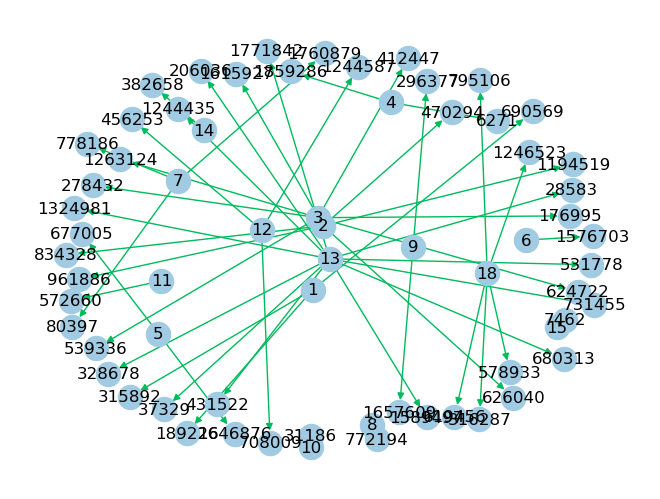

In [6]:
if not os.path.isfile('train_woheader_sample.csv'):
    pd.read_csv('train.csv', nrows=50).to_csv('train_woheader_sample.csv',header=False,index=False)
    
subgraph=nx.read_edgelist('train_woheader_sample.csv',delimiter=',',create_using=nx.DiGraph(),nodetype=int)
# https://stackoverflow.com/questions/9402255/drawing-a-huge-graph-with-networkx-and-matplotlib

pos=nx.spring_layout(subgraph)
nx.draw(subgraph,pos,node_color='#A0CBE2',edge_color='#00bb5e',width=1,edge_cmap=plt.cm.Blues,with_labels=True)
# Instead of nx.info(subgraph), use:
print(f"Graph Info:")
print(f"Number of nodes: {subgraph.number_of_nodes()}")
print(f"Number of edges: {subgraph.number_of_edges()}")
print(f"Graph type: {type(subgraph)}")

# 1. Exploratory Data Analysis

In [6]:
# No of Unique persons 
print("The number of unique persons",len(g.nodes()))

The number of unique persons 1862220


## 1.1 No of followers for each person

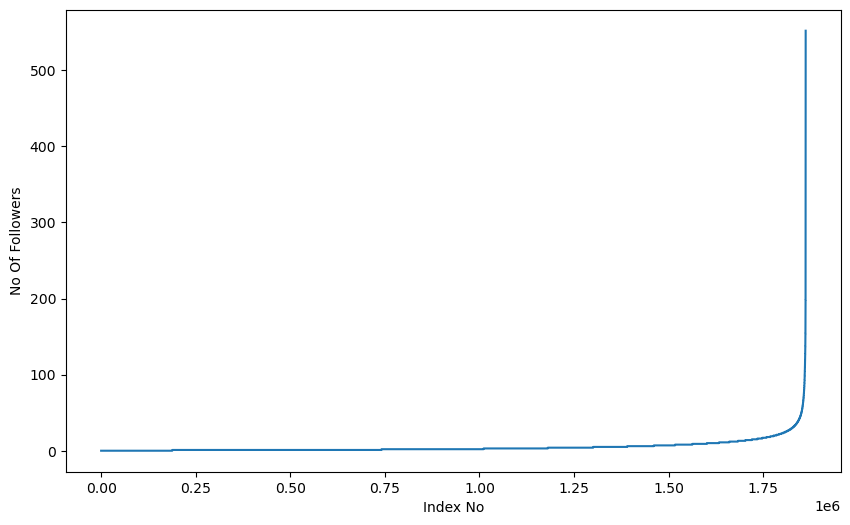

In [7]:
indegree_dist = list(dict(g.in_degree()).values())
indegree_dist.sort()
plt.figure(figsize=(10,6))
plt.plot(indegree_dist)
plt.xlabel('Index No')
plt.ylabel('No Of Followers')
plt.show()

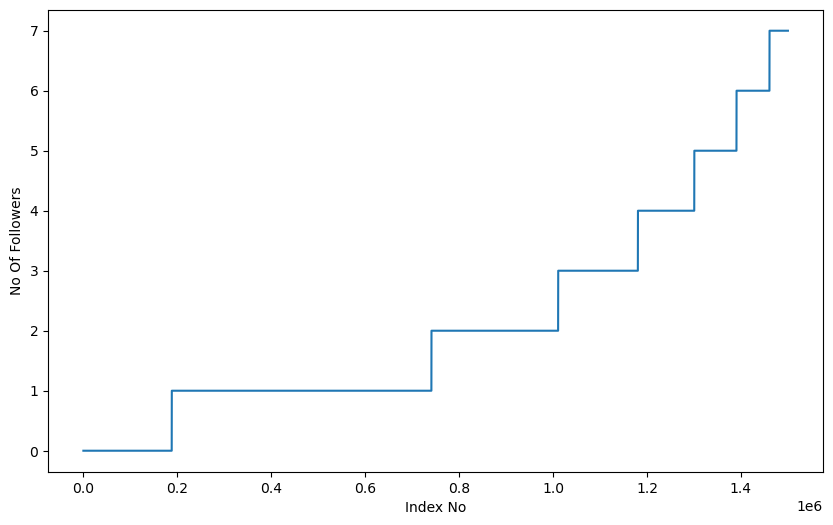

In [8]:
indegree_dist = list(dict(g.in_degree()).values())
indegree_dist.sort()
plt.figure(figsize=(10,6))
plt.plot(indegree_dist[0:1500000])
plt.xlabel('Index No')
plt.ylabel('No Of Followers')
plt.show()

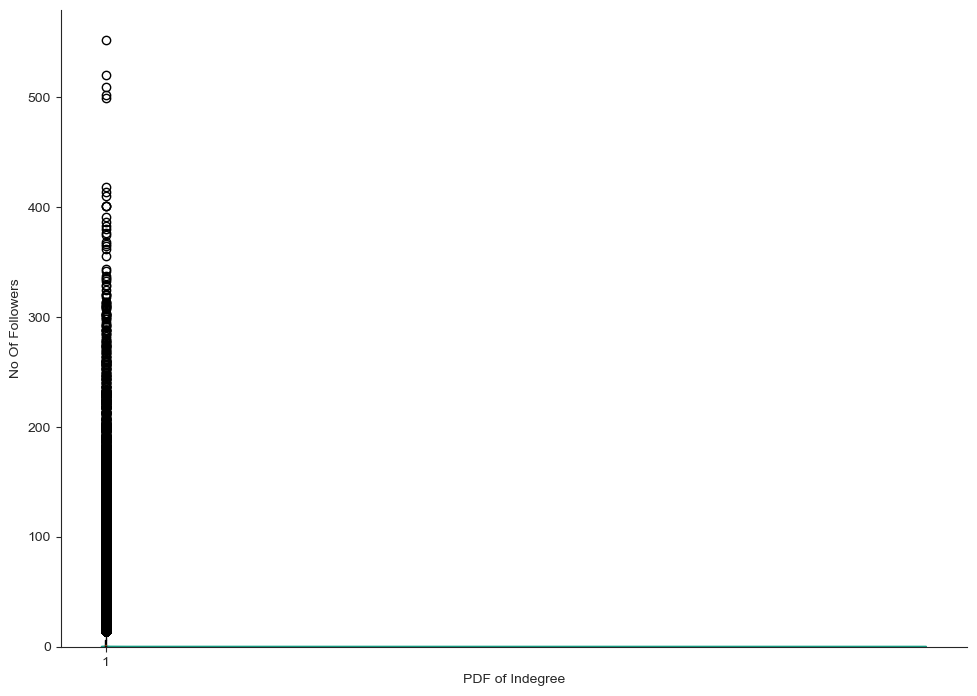

In [15]:
plt.boxplot(indegree_dist)
plt.ylabel('No Of Followers')
plt.show()

In [10]:
### 90-100 percentile  - do refer properly since it is percentile not percentage
for i in range(0,11):
    print(90+i,'percentile value is',np.percentile(indegree_dist,90+i))

90 percentile value is 12.0
91 percentile value is 13.0
92 percentile value is 14.0
93 percentile value is 15.0
94 percentile value is 17.0
95 percentile value is 19.0
96 percentile value is 21.0
97 percentile value is 24.0
98 percentile value is 29.0
99 percentile value is 40.0
100 percentile value is 552.0


99% of data having followers of 40 only.

In [11]:
### 99-100 percentile
for i in range(10,110,10):
    print(99+(i/100),'percentile value is',np.percentile(indegree_dist,99+(i/100)))

99.1 percentile value is 42.0
99.2 percentile value is 44.0
99.3 percentile value is 47.0
99.4 percentile value is 50.0
99.5 percentile value is 55.0
99.6 percentile value is 61.0
99.7 percentile value is 70.0
99.8 percentile value is 84.0
99.9 percentile value is 112.0
100.0 percentile value is 552.0


In [21]:
# Finding the user with highest number of followers
indegree_dict = dict(g.in_degree())
max_followers_user = max(indegree_dict, key=indegree_dict.get)
max_followers_count = indegree_dict[max_followers_user]

print(f"User with highest followers: {max_followers_user}")
print(f"Number of followers: {max_followers_count}")

# Let's also find top 10 users with most followers
top_10_users = sorted(indegree_dict.items(), key=lambda x: x[1], reverse=True)[:10]
print("\nTop 10 users with most followers:")
for i, (user, followers) in enumerate(top_10_users, 1):
    print(f"{i}. User {user}: {followers} followers")

User with highest followers: 415069
Number of followers: 552

Top 10 users with most followers:
1. User 415069: 552 followers
2. User 764866: 520 followers
3. User 1163921: 509 followers
4. User 1025567: 502 followers
5. User 1005648: 499 followers
6. User 99403: 418 followers
7. User 1506254: 414 followers
8. User 902162: 410 followers
9. User 1190227: 401 followers
10. User 1742231: 401 followers


## 1.2 No of people each person is following

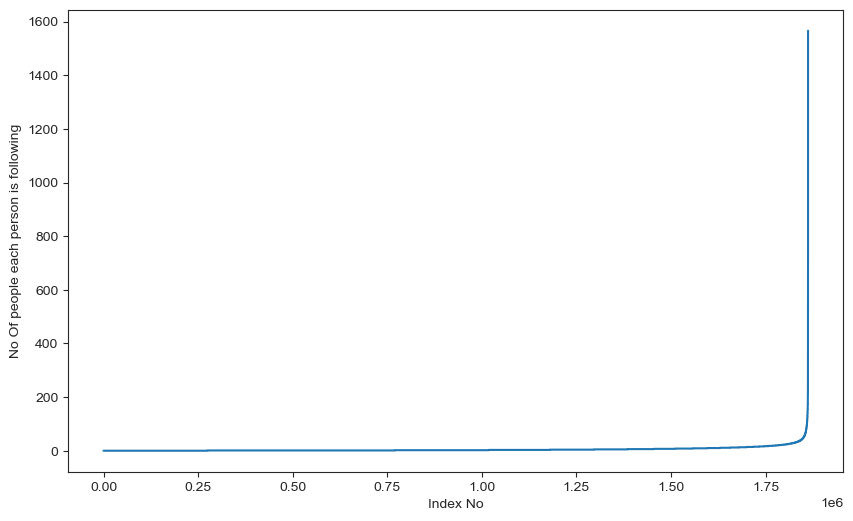

In [22]:
outdegree_dist = list(dict(g.out_degree()).values())
outdegree_dist.sort()
plt.figure(figsize=(10,6))
plt.plot(outdegree_dist)
plt.xlabel('Index No')
plt.ylabel('No Of people each person is following')
plt.show()

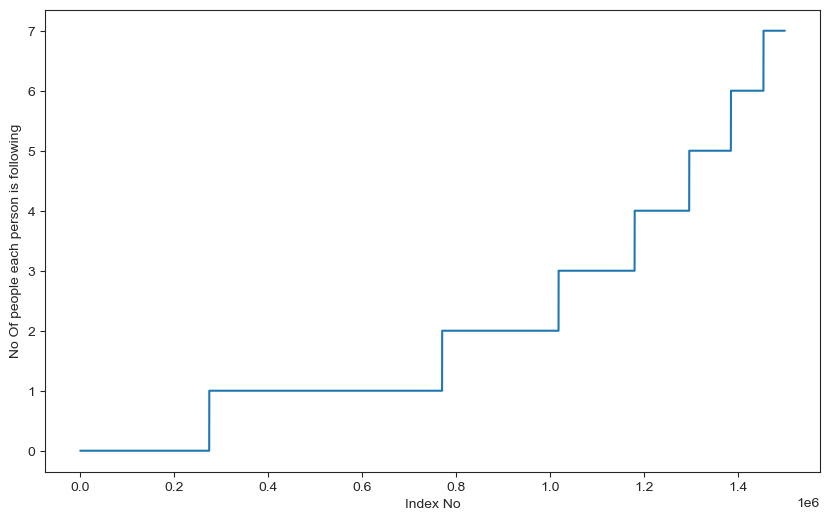

In [23]:
indegree_dist = list(dict(g.in_degree()).values())
indegree_dist.sort()
plt.figure(figsize=(10,6))
plt.plot(outdegree_dist[0:1500000])
plt.xlabel('Index No')
plt.ylabel('No Of people each person is following')
plt.show()

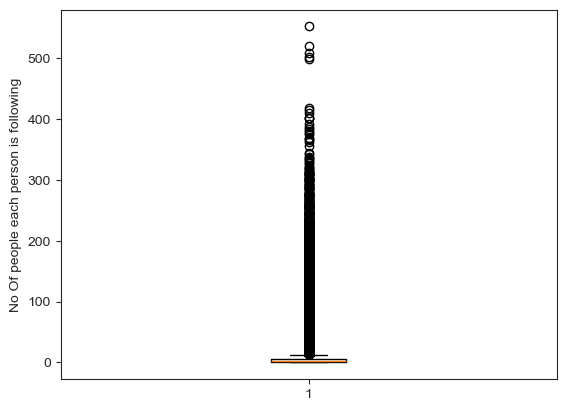

In [24]:
plt.boxplot(indegree_dist)
plt.ylabel('No Of people each person is following')
plt.show()

In [25]:
### 90-100 percentile
for i in range(0,11):
    print(90+i,'percentile value is',np.percentile(outdegree_dist,90+i))

90 percentile value is 12.0
91 percentile value is 13.0
92 percentile value is 14.0
93 percentile value is 15.0
94 percentile value is 17.0
95 percentile value is 19.0
96 percentile value is 21.0
97 percentile value is 24.0
98 percentile value is 29.0
99 percentile value is 40.0
100 percentile value is 1566.0
95 percentile value is 19.0
96 percentile value is 21.0
97 percentile value is 24.0
98 percentile value is 29.0
99 percentile value is 40.0
100 percentile value is 1566.0


In [26]:
### 99-100 percentile
for i in range(10,110,10):
    print(99+(i/100),'percentile value is',np.percentile(outdegree_dist,99+(i/100)))

99.1 percentile value is 42.0
99.2 percentile value is 45.0
99.3 percentile value is 48.0
99.4 percentile value is 52.0
99.5 percentile value is 56.0
99.6 percentile value is 63.0
99.7 percentile value is 73.0
99.8 percentile value is 90.0
99.9 percentile value is 123.0
100.0 percentile value is 1566.0
99.6 percentile value is 63.0
99.7 percentile value is 73.0
99.8 percentile value is 90.0
99.9 percentile value is 123.0
100.0 percentile value is 1566.0


In [28]:
sns.set_style('ticks')
fig, ax = plt.subplots()
fig.set_size_inches(11.7, 8.27)
sns.displot(outdegree_dist, color='#16A085')
plt.xlabel('PDF of Outdegree')
sns.despine()

In [29]:
print('No of persons those are not following anyone are' ,sum(np.array(outdegree_dist)==0),'and % is',
                                sum(np.array(outdegree_dist)==0)*100/len(outdegree_dist) )

No of persons those are not following anyone are 274512 and % is 14.741115442858524


In [30]:
print('No of persons having zero followers are' ,sum(np.array(indegree_dist)==0),'and % is',
                                sum(np.array(indegree_dist)==0)*100/len(indegree_dist) )

No of persons having zero followers are 188043 and % is 10.097786512871734


In [32]:
count=0
for i in g.nodes():
    if len(list(g.predecessors(i)))==0 :
        if len(list(g.successors(i)))==0:
            count+=1
print('No of persons those are not not following anyone and also not having any followers are',count)

No of persons those are not not following anyone and also not having any followers are 0


## 1.3 both followers + following 

In [33]:
from collections import Counter
dict_in = dict(g.in_degree())
dict_out = dict(g.out_degree())
d = Counter(dict_in) + Counter(dict_out)
in_out_degree = np.array(list(d.values()))

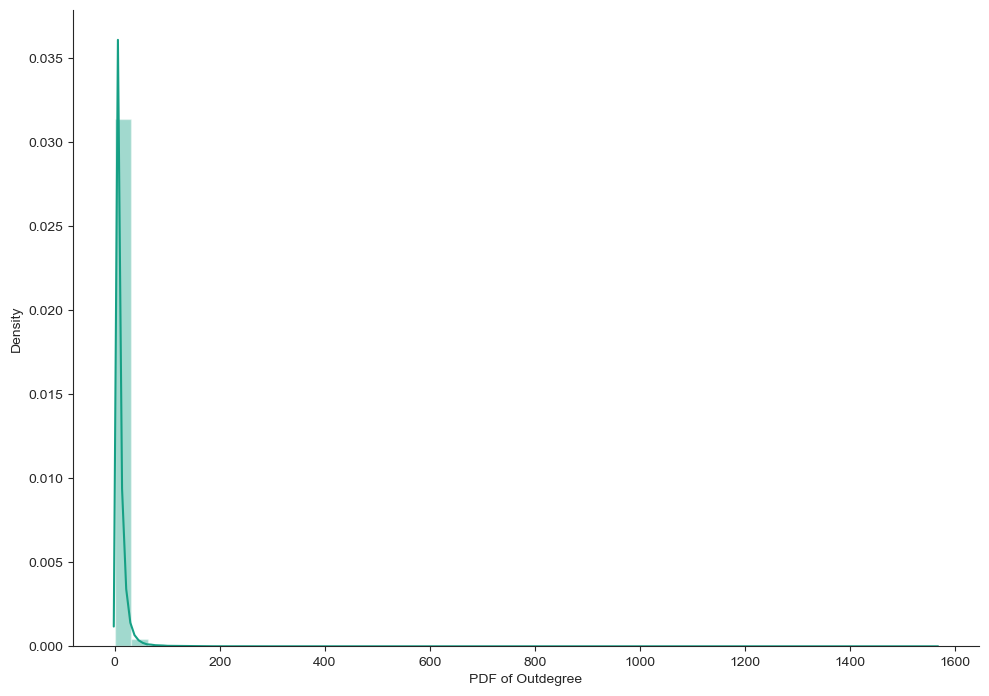

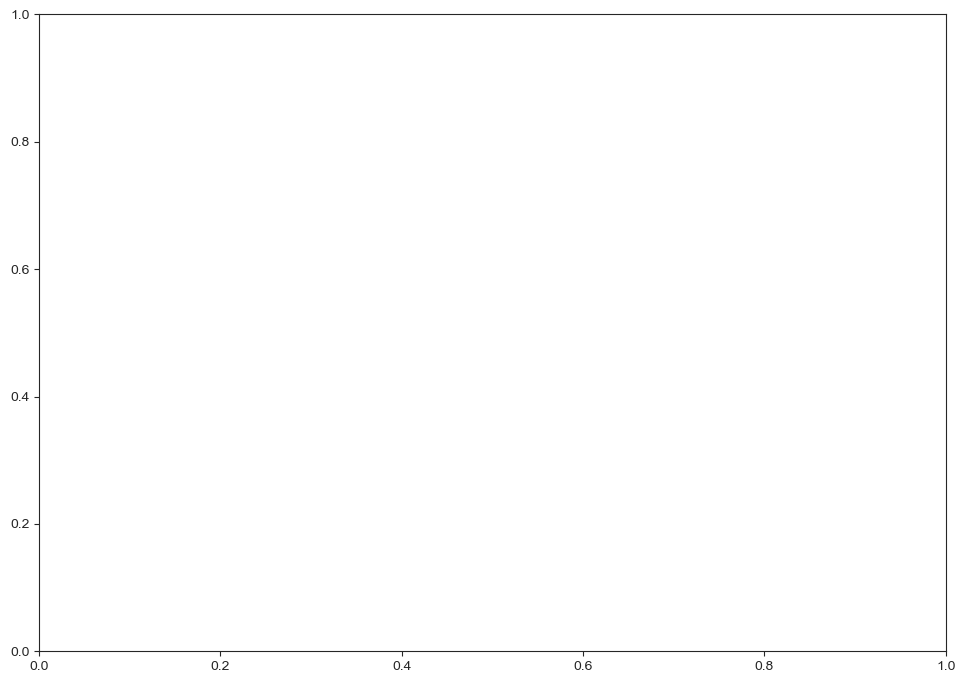

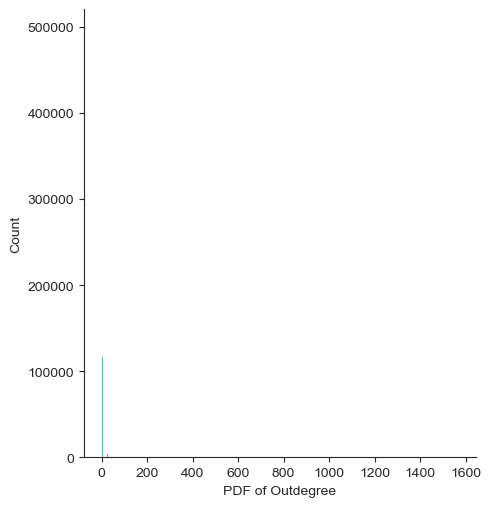

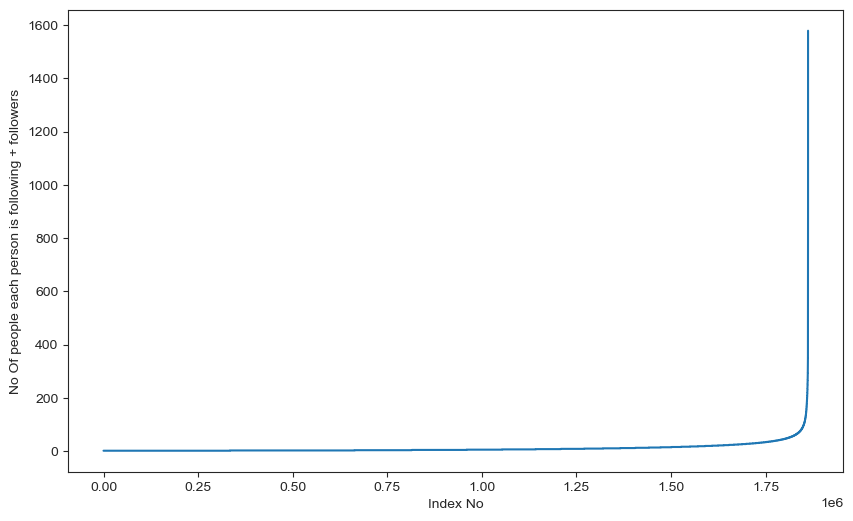

In [34]:
in_out_degree_sort = sorted(in_out_degree)
plt.figure(figsize=(10,6))
plt.plot(in_out_degree_sort)
plt.xlabel('Index No')
plt.ylabel('No Of people each person is following + followers')
plt.show()

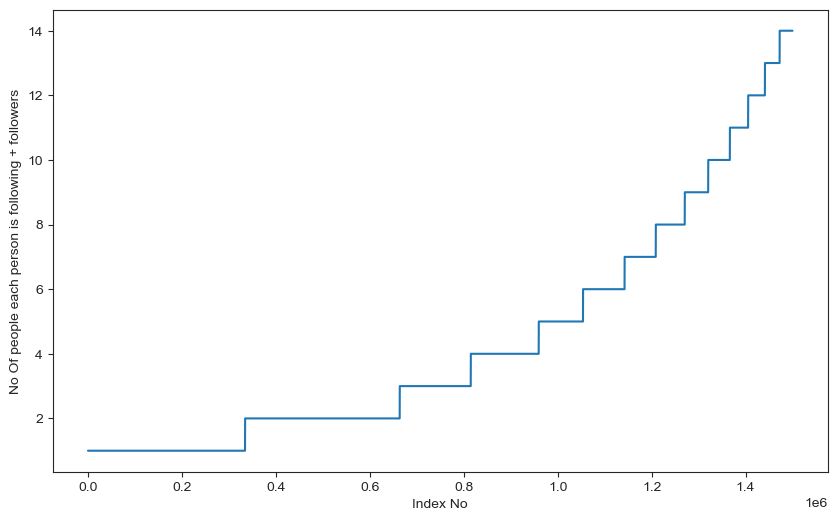

In [35]:
in_out_degree_sort = sorted(in_out_degree)
plt.figure(figsize=(10,6))
plt.plot(in_out_degree_sort[0:1500000])
plt.xlabel('Index No')
plt.ylabel('No Of people each person is following + followers')
plt.show()

In [36]:
### 90-100 percentile
for i in range(0,11):
    print(90+i,'percentile value is',np.percentile(in_out_degree_sort,90+i))

90 percentile value is 24.0
91 percentile value is 26.0
92 percentile value is 28.0
93 percentile value is 31.0
94 percentile value is 33.0
92 percentile value is 28.0
93 percentile value is 31.0
94 percentile value is 33.0
95 percentile value is 37.0
96 percentile value is 41.0
97 percentile value is 48.0
95 percentile value is 37.0
96 percentile value is 41.0
97 percentile value is 48.0
98 percentile value is 58.0
99 percentile value is 79.0
100 percentile value is 1579.0
98 percentile value is 58.0
99 percentile value is 79.0
100 percentile value is 1579.0


In [37]:
### 99-100 percentile
for i in range(10,110,10):
    print(99+(i/100),'percentile value is',np.percentile(in_out_degree_sort,99+(i/100)))

99.1 percentile value is 83.0
99.2 percentile value is 87.0
99.3 percentile value is 93.0
99.4 percentile value is 99.0
99.5 percentile value is 108.0
99.6 percentile value is 120.0
99.4 percentile value is 99.0
99.5 percentile value is 108.0
99.6 percentile value is 120.0
99.7 percentile value is 138.0
99.8 percentile value is 168.0
99.9 percentile value is 221.0
100.0 percentile value is 1579.0
99.7 percentile value is 138.0
99.8 percentile value is 168.0
99.9 percentile value is 221.0
100.0 percentile value is 1579.0


In [38]:
print('Min of no of followers + following is',in_out_degree.min())
print(np.sum(in_out_degree==in_out_degree.min()),' persons having minimum no of followers + following')

Min of no of followers + following is 1
334291  persons having minimum no of followers + following


In [39]:
print('Max of no of followers + following is',in_out_degree.max())
print(np.sum(in_out_degree==in_out_degree.max()),' persons having maximum no of followers + following')

Max of no of followers + following is 1579
1  persons having maximum no of followers + following


In [40]:
print('No of persons having followers + following less than 10 are',np.sum(in_out_degree<10))

No of persons having followers + following less than 10 are 1320326


In [41]:
print('No of weakly connected components',len(list(nx.weakly_connected_components(g))))
count=0
for i in list(nx.weakly_connected_components(g)):
    if len(i)==2:
        count+=1
print('weakly connected components wit 2 nodes',count)

No of weakly connected components 45558
weakly connected components wit 2 nodes 32195
weakly connected components wit 2 nodes 32195


In [5]:
%%time
###generating bad edges from given graph
import random
if not os.path.isfile('missing_edges_final.p'):
    #getting all set of edges
    r = csv.reader(open('train_woheader.csv','r'))
    edges = dict()
    for edge in r:
        edges[(edge[0], edge[1])] = 1
        
        
    missing_edges = set([])
    while (len(missing_edges)<9437519):
        a=random.randint(1, 1862220)
        b=random.randint(1, 1862220)
        tmp = edges.get((a,b),-1)
        if tmp == -1 and a!=b:
            try:
                if nx.shortest_path_length(g,source=a,target=b) > 2: 

                    missing_edges.add((a,b))
                else:
                    continue  
            except:  
                    missing_edges.add((a,b))              
        else:
            continue
    pickle.dump(missing_edges,open('missing_edges_final.p','wb'))
else:
    missing_edges = pickle.load(open('missing_edges_final.p','rb'))
    """This output is from the %%time magic command at the beginning of your code cell. Let me explain what these timing measurements mean:

What These Times Mean:
CPU times: total: 56.1 s
CPU Time: The actual time the processor spent working on your code
56.1 seconds: Your code used 56.1 seconds of pure CPU processing time
This is the "thinking time" - time spent on calculations, loops, and computations
Wall time: 1min 2s (62 seconds)
Wall Time: The real-world time that passed from start to finish
62 seconds: It took 62 seconds on the wall clock to complete
This includes everything: CPU work + waiting time
Why Are They Different?
The difference (62s - 56.1s = ~6 seconds) represents time spent on:

File I/O: Reading/writing files (train_woheader.csv, missing_edges_final.p)
Memory operations: Loading data into RAM
System overhead: Operating system managing the process
Disk access: Waiting for hard drive/SSD to respond"""

CPU times: total: 56.1 s
Wall time: 1min 2s


In [6]:
len(missing_edges)

9437519

## 2.2 Training and Test data split:  
Removed edges from Graph and used as test data and after removing used that graph for creating features for Train and test data

In [8]:
from sklearn.model_selection import train_test_split
if (not os.path.isfile('train_pos_after_eda.csv')) and (not os.path.isfile('test_pos_after_eda.csv')):
    #reading total data df
    df_pos = pd.read_csv('train.csv')
    df_neg = pd.DataFrame(list(missing_edges), columns=['source_node', 'destination_node'])
    
    print("Number of nodes in the graph with edges", df_pos.shape[0])
    print("Number of nodes in the graph without edges", df_neg.shape[0])
    
    #Trian test split 
    #Spiltted data into 80-20 
    #positive links and negative links seperatly because we need positive training data only for creating graph 
    #and for feature generation
    X_train_pos, X_test_pos, y_train_pos, y_test_pos  = train_test_split(df_pos,np.ones(len(df_pos)),test_size=0.2, random_state=9)
    X_train_neg, X_test_neg, y_train_neg, y_test_neg  = train_test_split(df_neg,np.zeros(len(df_neg)),test_size=0.2, random_state=9)
    
    print('='*60)
    print("Number of nodes in the train data graph with edges", X_train_pos.shape[0],"=",y_train_pos.shape[0])
    print("Number of nodes in the train data graph without edges", X_train_neg.shape[0],"=", y_train_neg.shape[0])
    print('='*60)
    print("Number of nodes in the test data graph with edges", X_test_pos.shape[0],"=",y_test_pos.shape[0])
    print("Number of nodes in the test data graph without edges", X_test_neg.shape[0],"=",y_test_neg.shape[0])

    #removing header and saving
    X_train_pos.to_csv('train_pos_after_eda.csv',header=False, index=False)
    X_test_pos.to_csv('test_pos_after_eda.csv',header=False, index=False)
    X_train_neg.to_csv('train_neg_after_eda.csv',header=False, index=False)
    X_test_neg.to_csv('test_neg_after_eda.csv',header=False, index=False)
else:
    #Graph from Traing data only 
    del missing_edges

Number of nodes in the graph with edges 9437519
Number of nodes in the graph without edges 9437519
Number of nodes in the train data graph with edges 7550015 = 7550015
Number of nodes in the train data graph without edges 7550015 = 7550015
Number of nodes in the test data graph with edges 1887504 = 1887504
Number of nodes in the test data graph without edges 1887504 = 1887504
Number of nodes in the train data graph with edges 7550015 = 7550015
Number of nodes in the train data graph without edges 7550015 = 7550015
Number of nodes in the test data graph with edges 1887504 = 1887504
Number of nodes in the test data graph without edges 1887504 = 1887504


In [17]:
if (os.path.isfile('train_pos_after_eda.csv')) and (os.path.isfile('test_pos_after_eda.csv')):        
    train_graph=nx.read_edgelist('train_pos_after_eda.csv',delimiter=',',create_using=nx.DiGraph(),nodetype=int)
    test_graph=nx.read_edgelist('test_pos_after_eda.csv',delimiter=',',create_using=nx.DiGraph(),nodetype=int)
    
    # Train graph info
    print(f"Train Graph Info:")
    print(f"Number of nodes: {train_graph.number_of_nodes()}")
    print(f"Number of edges: {train_graph.number_of_edges()}")
    print(f"Graph type: {type(train_graph)}")
    
    # Test graph info
    print(f"\nTest Graph Info:")
    print(f"Number of nodes: {test_graph.number_of_nodes()}")
    print(f"Number of edges: {test_graph.number_of_edges()}")
    print(f"Graph type: {type(test_graph)}")

    # finding the unique nodes in the both train and test graphs
    train_nodes_pos = set(train_graph.nodes())
    test_nodes_pos = set(test_graph.nodes())

    trY_teY = len(train_nodes_pos.intersection(test_nodes_pos))
    trY_teN = len(train_nodes_pos - test_nodes_pos)
    teY_trN = len(test_nodes_pos - train_nodes_pos)

    print('no of people common in train and test -- ',trY_teY)
    print('no of people present in train but not present in test -- ',trY_teN)

    print('no of people present in test but not present in train -- ',teY_trN)
    print(' % of people not there in Train but exist in Test in total Test data are {} %'.format(teY_trN/len(test_nodes_pos)*100))

Train Graph Info:
Number of nodes: 1780722
Number of edges: 7550015
Graph type: <class 'networkx.classes.digraph.DiGraph'>

Test Graph Info:
Number of nodes: 1144623
Number of edges: 7550015
Graph type: <class 'networkx.classes.digraph.DiGraph'>

Test Graph Info:
Number of nodes: 1144623
Number of edges: 1887504
Graph type: <class 'networkx.classes.digraph.DiGraph'>
no of people common in train and test --  1063125
no of people present in train but not present in test --  717597
no of people present in test but not present in train --  81498
 % of people not there in Train but exist in Test in total Test data are 7.1200735962845405 %
Number of edges: 1887504
Graph type: <class 'networkx.classes.digraph.DiGraph'>
no of people common in train and test --  1063125
no of people present in train but not present in test --  717597
no of people present in test but not present in train --  81498
 % of people not there in Train but exist in Test in total Test data are 7.1200735962845405 %


> we have a cold start problem here

In [23]:
#final train and test data sets
if (not os.path.isfile('train_after_eda.csv')) and \
(not os.path.isfile('test_after_eda.csv')) and \
(not os.path.isfile('train_y.csv')) and \
(not os.path.isfile('test_y.csv')) and \
(os.path.isfile('train_pos_after_eda.csv')) and \
(os.path.isfile('test_pos_after_eda.csv')) and \
(os.path.isfile('train_neg_after_eda.csv')) and \
(os.path.isfile('test_neg_after_eda.csv')):
    
    X_train_pos = pd.read_csv('train_pos_after_eda.csv', names=['source_node', 'destination_node'])
    X_test_pos = pd.read_csv('test_pos_after_eda.csv', names=['source_node', 'destination_node'])
    X_train_neg = pd.read_csv('train_neg_after_eda.csv', names=['source_node', 'destination_node'])
    X_test_neg = pd.read_csv('test_neg_after_eda.csv', names=['source_node', 'destination_node'])

    print('='*60)
    print("Number of nodes in the train data graph with edges", X_train_pos.shape[0])
    print("Number of nodes in the train data graph without edges", X_train_neg.shape[0])
    print('='*60)
    print("Number of nodes in the test data graph with edges", X_test_pos.shape[0])
    print("Number of nodes in the test data graph without edges", X_test_neg.shape[0])

    X_train = pd.concat([X_train_pos, X_train_neg], ignore_index=True)
    y_train = np.concatenate((y_train_pos,y_train_neg))
    X_test = pd.concat([X_test_pos, X_test_neg], ignore_index=True)
    y_test = np.concatenate((y_test_pos,y_test_neg)) 
    
    X_train.to_csv('train_after_eda.csv',header=False,index=False)
    X_test.to_csv('test_after_eda.csv',header=False,index=False)
    pd.DataFrame(y_train.astype(int)).to_csv('train_y.csv',header=False,index=False)
    pd.DataFrame(y_test.astype(int)).to_csv('test_y.csv',header=False,index=False)

Number of nodes in the train data graph with edges 7550015
Number of nodes in the train data graph without edges 7550015
Number of nodes in the test data graph with edges 1887504
Number of nodes in the test data graph without edges 1887504


In [24]:
print("Data points in train data",X_train.shape)
print("Data points in test data",X_test.shape)
print("Shape of traget variable in train",y_train.shape)
print("Shape of traget variable in test", y_test.shape)

Data points in train data (15100030, 2)
Data points in test data (3775008, 2)
Shape of traget variable in train (15100030,)
Shape of traget variable in test (3775008,)



FOLLOWERS - DETAILED INSIGHTS
10% of people have ≤      3 followers
   → 90% of people have >      3 followers
25% of people have ≤      4 followers
   → 75% of people have >      4 followers
50% of people have ≤      6 followers
   → 50% of people have >      6 followers
25% of people have ≤      4 followers
   → 75% of people have >      4 followers
50% of people have ≤      6 followers
   → 50% of people have >      6 followers
75% of people have ≤      9 followers
   → 25% of people have >      9 followers
90% of people have ≤     14 followers
   → 10% of people have >     14 followers
75% of people have ≤      9 followers
   → 25% of people have >      9 followers
90% of people have ≤     14 followers
   → 10% of people have >     14 followers
95% of people have ≤     19 followers
   →  5% of people have >     19 followers
99% of people have ≤     37 followers
   →  1% of people have >     37 followers

KEY INSIGHTS:
95% of people have ≤     19 followers
   →  5% of people have >

C:\Users\Aditya\AppData\Local\Temp\ipykernel_7492\4065564689.py:158: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = plt.boxplot(data_to_plot, labels=['Followers', 'Following', 'Total'], patch_artist=True)
C:\Users\Aditya\AppData\Local\Temp\ipykernel_7492\4065564689.py:167: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Aditya\AppData\Local\Temp\ipykernel_7492\4065564689.py:167: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\Aditya\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Aditya\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend wi

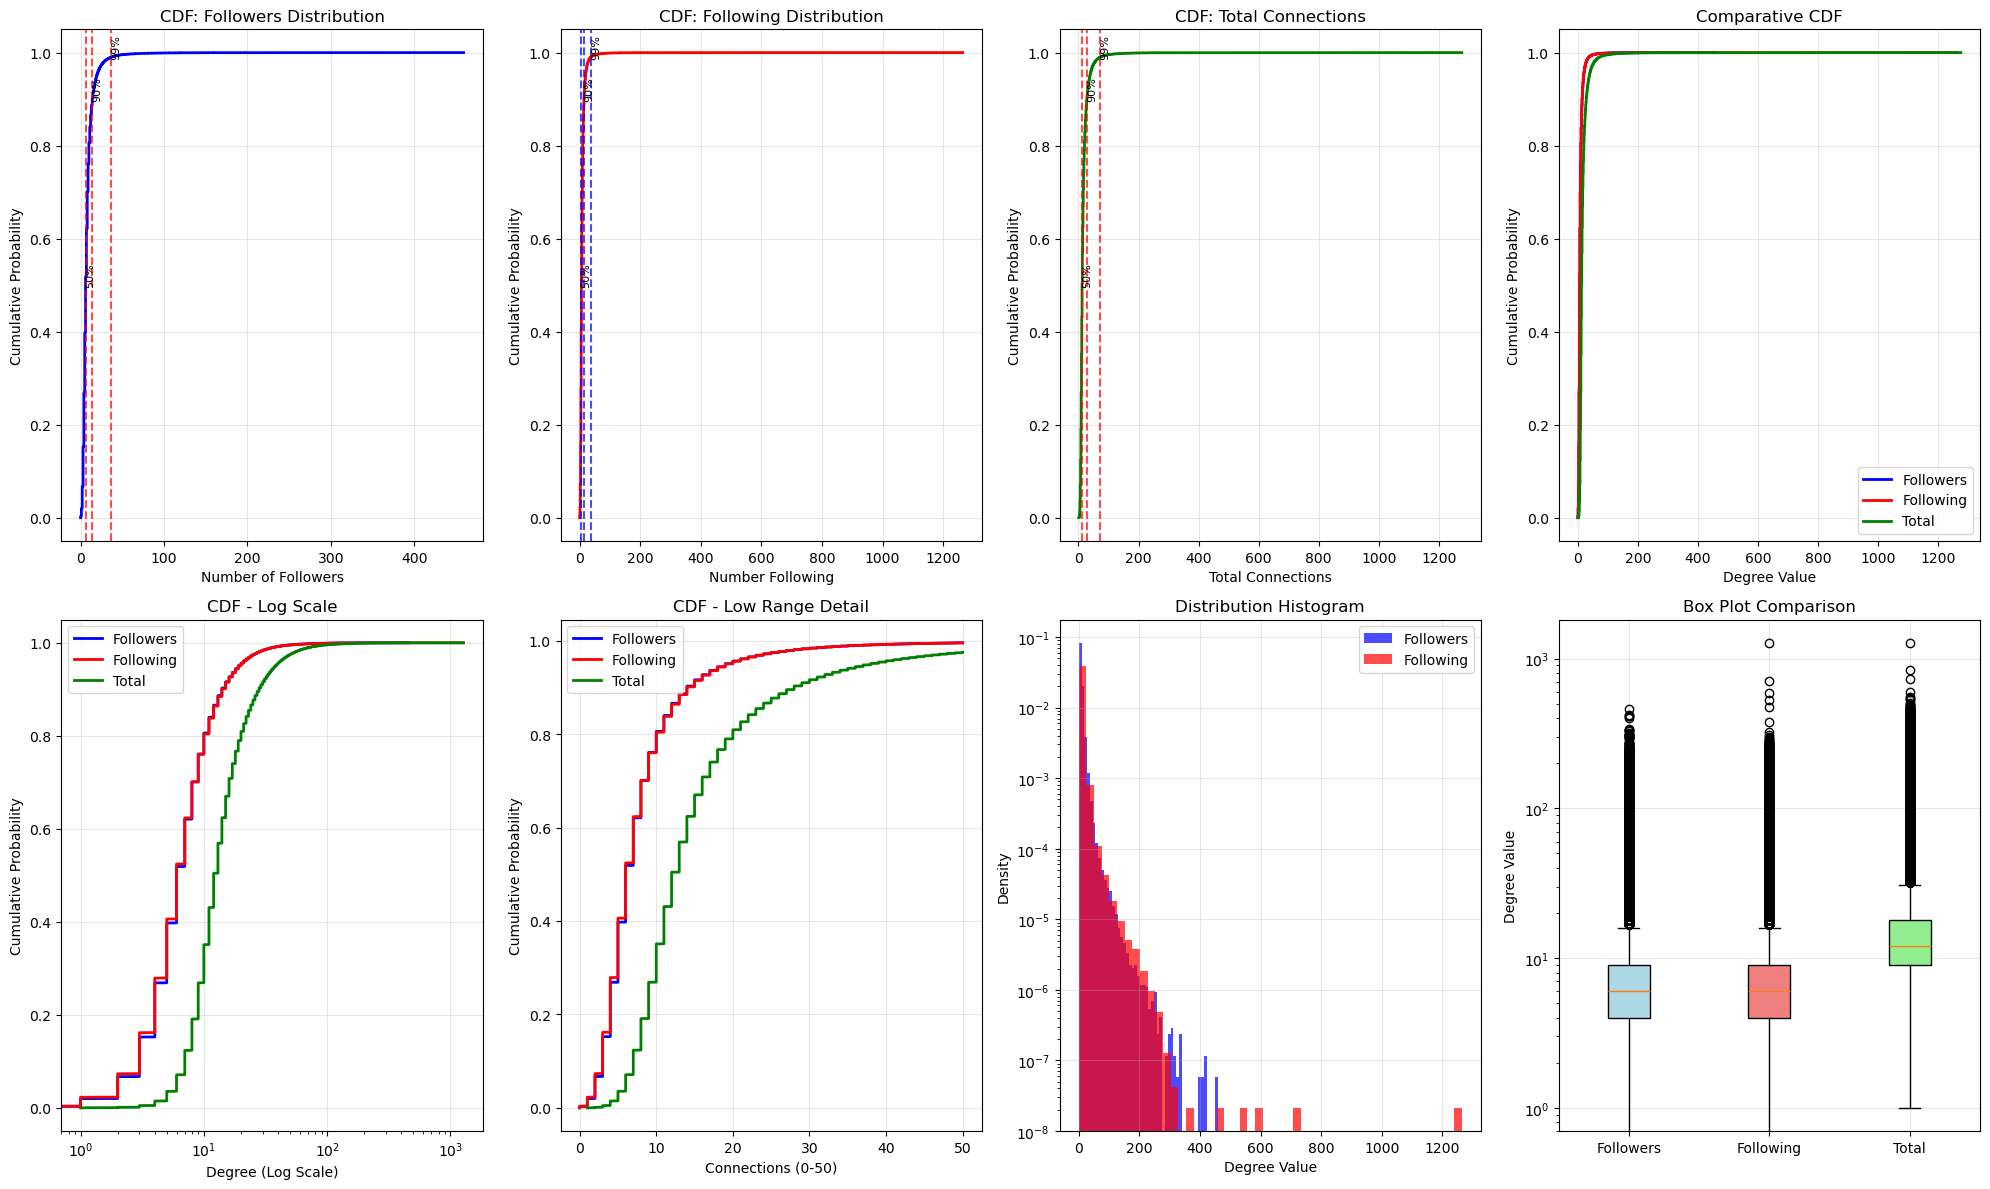


FACEBOOK FRIEND RECOMMENDATION - COMPREHENSIVE DATA INSIGHTS
Dataset Overview:
• Total nodes in network: 1,862,201
• Total edges (friendships): 15,100,016
• Training examples: 15,100,030
• Positive examples (friends): 7,550,015
• Negative examples (non-friends): 7,550,015

Network Characteristics:
• Total edges (friendships): 15,100,016
• Training examples: 15,100,030
• Positive examples (friends): 7,550,015
• Negative examples (non-friends): 7,550,015

Network Characteristics:
• Average followers per person: 8.1
• Average following per person: 8.1
• Average total connections: 16.2

Key Findings:
• Average followers per person: 8.1
• Average following per person: 8.1
• Average total connections: 16.2

Key Findings:
• 50% of people have ≤ 6 followers
• 50% of people follow ≤ 6 others
• Top 1% have > 37 followers (influencers)
• 50% of people have ≤ 6 followers
• 50% of people follow ≤ 6 others
• Top 1% have > 37 followers (influencers)
• 5,545 people have zero followers (0.3%)
• 6,783 

In [1]:
# Comprehensive CDF Analysis and Insights for Facebook Friend Recommendation Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter

# Load the final training data
train_data = pd.read_csv('train_after_eda.csv', names=['source_node', 'destination_node'])
target_data = pd.read_csv('train_y.csv', names=['target'])

# Create graph from training data
train_final_graph = nx.from_pandas_edgelist(train_data, 
                                           source='source_node', 
                                           target='destination_node', 
                                           create_using=nx.DiGraph())

# Calculate degree distributions
in_degree_final = list(dict(train_final_graph.in_degree()).values())
out_degree_final = list(dict(train_final_graph.out_degree()).values())

# Combined degree (in + out)
dict_in_final = dict(train_final_graph.in_degree())
dict_out_final = dict(train_final_graph.out_degree())
combined_degree_final = Counter(dict_in_final) + Counter(dict_out_final)
total_degree_final = np.array(list(combined_degree_final.values()))

# CDF Calculation Function
def calculate_cdf_insights(data, title):
    sorted_data = np.sort(data)
    n = len(data)
    cdf_values = np.arange(1, n + 1) / n
    
    # Key percentiles
    percentiles = [10, 25, 50, 75, 90, 95, 99]
    print(f"\n{'='*60}")
    print(f"{title} - DETAILED INSIGHTS")
    print(f"{'='*60}")
    
    for p in percentiles:
        value = np.percentile(data, p)
        print(f"{p:2d}% of people have ≤ {value:6.0f} {title.lower()}")
        print(f"   → {100-p:2d}% of people have > {value:6.0f} {title.lower()}")
    
    # Special insights
    print(f"\nKEY INSIGHTS:")
    print(f"• Average {title.lower()}: {np.mean(data):.1f}")
    print(f"• Median {title.lower()}: {np.median(data):.0f}")
    print(f"• Maximum {title.lower()}: {np.max(data):,}")
    print(f"• Minimum {title.lower()}: {np.min(data)}")
    
    # Distribution categories
    zero_count = np.sum(np.array(data) == 0)
    low_count = np.sum((np.array(data) > 0) & (np.array(data) <= 10))
    medium_count = np.sum((np.array(data) > 10) & (np.array(data) <= 100))
    high_count = np.sum(np.array(data) > 100)
    
    print(f"\nDISTRIBUTION BREAKDOWN:")
    print(f"• Zero {title.lower()}: {zero_count:,} people ({zero_count/n*100:.1f}%)")
    print(f"• Low (1-10): {low_count:,} people ({low_count/n*100:.1f}%)")
    print(f"• Medium (11-100): {medium_count:,} people ({medium_count/n*100:.1f}%)")
    print(f"• High (>100): {high_count:,} people ({high_count/n*100:.1f}%)")
    
    return sorted_data, cdf_values

# Generate insights for all three distributions
sorted_in, cdf_in = calculate_cdf_insights(in_degree_final, "FOLLOWERS")
sorted_out, cdf_out = calculate_cdf_insights(out_degree_final, "FOLLOWING")
sorted_total, cdf_total = calculate_cdf_insights(total_degree_final, "TOTAL CONNECTIONS")

# Comprehensive visualization
plt.figure(figsize=(20, 12))

# 1. Individual CDFs
plt.subplot(2, 4, 1)
plt.plot(sorted_in, cdf_in, linewidth=2, color='blue', label='Followers')
plt.xlabel('Number of Followers')
plt.ylabel('Cumulative Probability')
plt.title('CDF: Followers Distribution')
plt.grid(True, alpha=0.3)
for p in [50, 90, 99]:
    val = np.percentile(in_degree_final, p)
    plt.axvline(x=val, color='red', linestyle='--', alpha=0.7)
    plt.text(val, p/100, f'{p}%', rotation=90, fontsize=8)

plt.subplot(2, 4, 2)
plt.plot(sorted_out, cdf_out, linewidth=2, color='red', label='Following')
plt.xlabel('Number Following')
plt.ylabel('Cumulative Probability')
plt.title('CDF: Following Distribution')
plt.grid(True, alpha=0.3)
for p in [50, 90, 99]:
    val = np.percentile(out_degree_final, p)
    plt.axvline(x=val, color='blue', linestyle='--', alpha=0.7)
    plt.text(val, p/100, f'{p}%', rotation=90, fontsize=8)

plt.subplot(2, 4, 3)
plt.plot(sorted_total, cdf_total, linewidth=2, color='green', label='Total')
plt.xlabel('Total Connections')
plt.ylabel('Cumulative Probability')
plt.title('CDF: Total Connections')
plt.grid(True, alpha=0.3)
for p in [50, 90, 99]:
    val = np.percentile(total_degree_final, p)
    plt.axvline(x=val, color='red', linestyle='--', alpha=0.7)
    plt.text(val, p/100, f'{p}%', rotation=90, fontsize=8)

# 4. Comparative CDF
plt.subplot(2, 4, 4)
plt.plot(sorted_in, cdf_in, linewidth=2, color='blue', label='Followers')
plt.plot(sorted_out, cdf_out, linewidth=2, color='red', label='Following')
plt.plot(sorted_total, cdf_total, linewidth=2, color='green', label='Total')
plt.xlabel('Degree Value')
plt.ylabel('Cumulative Probability')
plt.title('Comparative CDF')
plt.legend()
plt.grid(True, alpha=0.3)

# 5. Log scale view
plt.subplot(2, 4, 5)
plt.semilogx(sorted_in, cdf_in, linewidth=2, color='blue', label='Followers')
plt.semilogx(sorted_out, cdf_out, linewidth=2, color='red', label='Following')
plt.semilogx(sorted_total, cdf_total, linewidth=2, color='green', label='Total')
plt.xlabel('Degree (Log Scale)')
plt.ylabel('Cumulative Probability')
plt.title('CDF - Log Scale')
plt.legend()
plt.grid(True, alpha=0.3)

# 6. Zoomed view (0-50)
plt.subplot(2, 4, 6)
mask_in = sorted_in <= 50
mask_out = sorted_out <= 50
mask_total = sorted_total <= 50
plt.plot(sorted_in[mask_in], cdf_in[mask_in], linewidth=2, color='blue', label='Followers')
plt.plot(sorted_out[mask_out], cdf_out[mask_out], linewidth=2, color='red', label='Following')
plt.plot(sorted_total[mask_total], cdf_total[mask_total], linewidth=2, color='green', label='Total')
plt.xlabel('Connections (0-50)')
plt.ylabel('Cumulative Probability')
plt.title('CDF - Low Range Detail')
plt.legend()
plt.grid(True, alpha=0.3)

# 7. Distribution histogram
plt.subplot(2, 4, 7)
plt.hist(in_degree_final, bins=50, alpha=0.7, color='blue', label='Followers', density=True)
plt.hist(out_degree_final, bins=50, alpha=0.7, color='red', label='Following', density=True)
plt.xlabel('Degree Value')
plt.ylabel('Density')
plt.title('Distribution Histogram')
plt.legend()
plt.yscale('log')
plt.grid(True, alpha=0.3)

# 8. Box plot comparison
plt.subplot(2, 4, 8)
data_to_plot = [in_degree_final, out_degree_final, total_degree_final]
box_plot = plt.boxplot(data_to_plot, labels=['Followers', 'Following', 'Total'], patch_artist=True)
colors = ['lightblue', 'lightcoral', 'lightgreen']
for patch, color in zip(box_plot['boxes'], colors):
    patch.set_facecolor(color)
plt.ylabel('Degree Value')
plt.title('Box Plot Comparison')
plt.yscale('log')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# SUMMARY INSIGHTS
print(f"\n{'='*80}")
print(f"FACEBOOK FRIEND RECOMMENDATION - COMPREHENSIVE DATA INSIGHTS")
print(f"{'='*80}")
print(f"Dataset Overview:")
print(f"• Total nodes in network: {train_final_graph.number_of_nodes():,}")
print(f"• Total edges (friendships): {train_final_graph.number_of_edges():,}")
print(f"• Training examples: {train_data.shape[0]:,}")
print(f"• Positive examples (friends): {(target_data['target'] == 1).sum():,}")
print(f"• Negative examples (non-friends): {(target_data['target'] == 0).sum():,}")

print(f"\nNetwork Characteristics:")
print(f"• Average followers per person: {np.mean(in_degree_final):.1f}")
print(f"• Average following per person: {np.mean(out_degree_final):.1f}")
print(f"• Average total connections: {np.mean(total_degree_final):.1f}")

print(f"\nKey Findings:")
followers_50 = np.percentile(in_degree_final, 50)
following_50 = np.percentile(out_degree_final, 50)
print(f"• 50% of people have ≤ {followers_50:.0f} followers")
print(f"• 50% of people follow ≤ {following_50:.0f} others")
print(f"• Top 1% have > {np.percentile(in_degree_final, 99):.0f} followers (influencers)")
print(f"• {np.sum(np.array(in_degree_final) == 0):,} people have zero followers ({np.sum(np.array(in_degree_final) == 0)/len(in_degree_final)*100:.1f}%)")
print(f"• {np.sum(np.array(out_degree_final) == 0):,} people follow nobody ({np.sum(np.array(out_degree_final) == 0)/len(out_degree_final)*100:.1f}%)")

print(f"\nRecommendation System Implications:")
print(f"• High variability in user activity (good for feature diversity)")
print(f"• Power-law distribution typical of social networks")
print(f"• Cold start challenge: Users with minimal connections")
print(f"• Rich feature space for graph-based recommendations")
print(f"{'='*80}")

COMPREHENSIVE DISTRIBUTION ANALYSIS WITH Q-Q PLOTS AND WEIBULL FITTING

DISTRIBUTION ANALYSIS: FOLLOWERS DISTRIBUTION
Basic Statistics:
• Mean: 9.11
• Median: 7.00
• Std Dev: 7.86
• Skewness: 8.00
• Kurtosis: 148.98
• Normal KS-test: statistic=0.2158, p-value=0.0000
• Exponential KS-test: statistic=0.2422, p-value=0.0000
• Normal KS-test: statistic=0.2158, p-value=0.0000
• Exponential KS-test: statistic=0.2422, p-value=0.0000
• Weibull KS-test: statistic=0.3975, p-value=0.0000
• Weibull KS-test: statistic=0.3975, p-value=0.0000
• Power Law KS-test: statistic=0.4672, p-value=0.0000
• Power Law KS-test: statistic=0.4672, p-value=0.0000
• Weibull Parameters: Shape=0.434, Location=6.000, Scale=1.303
• Weibull Parameters: Shape=0.434, Location=6.000, Scale=1.303


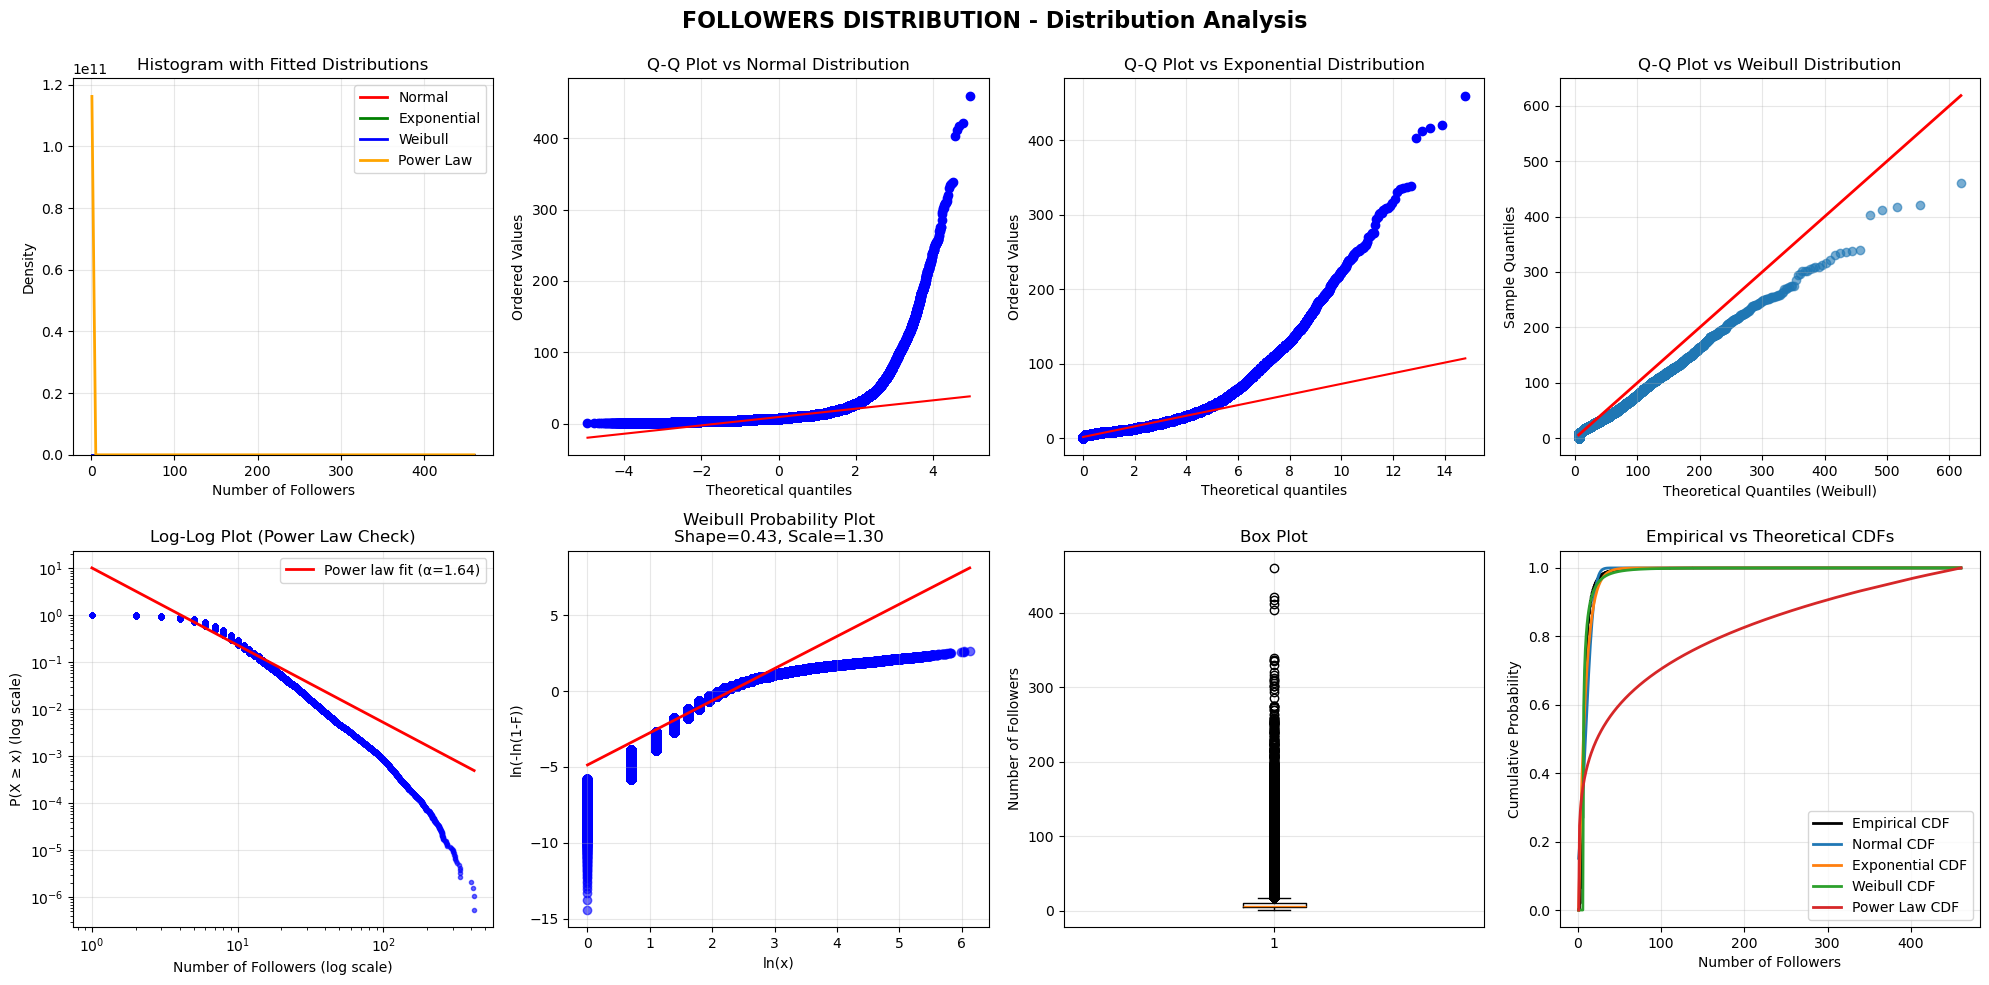


Weibull Distribution Analysis:
• Shape parameter (k): 0.434
• Scale parameter (λ): 1.303
• Location parameter: 6.000
• Distribution characteristic: Decreasing failure rate


TypeError: unsupported operand type(s) for *: 'float' and 'rv_continuous_frozen'

In [2]:
# Q-Q Plot and Weibull Distribution Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter
import scipy.stats as stats
from scipy.stats import weibull_min, norm, expon, powerlaw
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings('ignore')

# Load the final training data (if not already loaded)
train_data = pd.read_csv('train_after_eda.csv', names=['source_node', 'destination_node'])
target_data = pd.read_csv('train_y.csv', names=['target'])

# Create graph from training data
train_final_graph = nx.from_pandas_edgelist(train_data, 
                                           source='source_node', 
                                           target='destination_node', 
                                           create_using=nx.DiGraph())

# Calculate degree distributions
in_degree_final = list(dict(train_final_graph.in_degree()).values())
out_degree_final = list(dict(train_final_graph.out_degree()).values())

# Combined degree (in + out)
dict_in_final = dict(train_final_graph.in_degree())
dict_out_final = dict(train_final_graph.out_degree())
combined_degree_final = Counter(dict_in_final) + Counter(dict_out_final)
total_degree_final = np.array(list(combined_degree_final.values()))

# Remove zeros for better distribution fitting (add 1 to avoid log(0))
in_degree_nonzero = np.array(in_degree_final) + 1
out_degree_nonzero = np.array(out_degree_final) + 1
total_degree_nonzero = total_degree_final + 1

def analyze_distribution_with_qq_weibull(data, title, data_name):
    """
    Comprehensive distribution analysis with Q-Q plots and Weibull fitting
    """
    print(f"\n{'='*70}")
    print(f"DISTRIBUTION ANALYSIS: {title}")
    print(f"{'='*70}")
    
    # Basic statistics
    print(f"Basic Statistics:")
    print(f"• Mean: {np.mean(data):.2f}")
    print(f"• Median: {np.median(data):.2f}")
    print(f"• Std Dev: {np.std(data):.2f}")
    print(f"• Skewness: {stats.skew(data):.2f}")
    print(f"• Kurtosis: {stats.kurtosis(data):.2f}")
    
    # Create comprehensive plot
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    fig.suptitle(f'{title} - Distribution Analysis', fontsize=16, fontweight='bold')
    
    # 1. Histogram with fitted distributions
    ax1 = axes[0, 0]
    ax1.hist(data, bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='black')
    
    # Fit multiple distributions
    distributions = {
        'Normal': norm,
        'Exponential': expon,
        'Weibull': weibull_min,
        'Power Law': powerlaw
    }
    
    colors = ['red', 'green', 'blue', 'orange']
    fitted_params = {}
    
    for i, (dist_name, distribution) in enumerate(distributions.items()):
        try:
            # Fit distribution
            params = distribution.fit(data)
            fitted_params[dist_name] = params
            
            # Generate fitted curve
            x_range = np.linspace(data.min(), data.max(), 100)
            fitted_curve = distribution.pdf(x_range, *params)
            
            ax1.plot(x_range, fitted_curve, colors[i], linewidth=2, 
                    label=f'{dist_name}')
            
            # Calculate goodness of fit (Kolmogorov-Smirnov test)
            ks_stat, ks_p = stats.kstest(data, lambda x: distribution.cdf(x, *params))
            print(f"• {dist_name} KS-test: statistic={ks_stat:.4f}, p-value={ks_p:.4f}")
            
        except Exception as e:
            print(f"• {dist_name} fitting failed: {str(e)}")
    
    ax1.set_xlabel(f'{data_name}')
    ax1.set_ylabel('Density')
    ax1.set_title('Histogram with Fitted Distributions')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Q-Q Plot vs Normal Distribution
    ax2 = axes[0, 1]
    stats.probplot(data, dist="norm", plot=ax2)
    ax2.set_title('Q-Q Plot vs Normal Distribution')
    ax2.grid(True, alpha=0.3)
    
    # 3. Q-Q Plot vs Exponential Distribution
    ax3 = axes[0, 2]
    stats.probplot(data, dist="expon", plot=ax3)
    ax3.set_title('Q-Q Plot vs Exponential Distribution')
    ax3.grid(True, alpha=0.3)
    
    # 4. Q-Q Plot vs Weibull Distribution
    ax4 = axes[0, 3]
    if 'Weibull' in fitted_params:
        weibull_params = fitted_params['Weibull']
        # Create theoretical quantiles for Weibull
        sorted_data = np.sort(data)
        n = len(data)
        theoretical_quantiles = weibull_min.ppf(np.arange(1, n+1)/(n+1), *weibull_params)
        
        ax4.scatter(theoretical_quantiles, sorted_data, alpha=0.6)
        ax4.plot([theoretical_quantiles.min(), theoretical_quantiles.max()], 
                [theoretical_quantiles.min(), theoretical_quantiles.max()], 
                'r-', linewidth=2)
        ax4.set_xlabel('Theoretical Quantiles (Weibull)')
        ax4.set_ylabel('Sample Quantiles')
        ax4.set_title('Q-Q Plot vs Weibull Distribution')
        ax4.grid(True, alpha=0.3)
    
    # 5. Log-Log Plot (Power Law Check)
    ax5 = axes[1, 0]
    # Calculate complementary CDF (survival function)
    sorted_data = np.sort(data)
    n = len(data)
    ccdf = 1 - np.arange(1, n+1) / n
    
    # Remove zeros for log plot
    mask = (sorted_data > 0) & (ccdf > 0)
    if np.sum(mask) > 10:
        ax5.loglog(sorted_data[mask], ccdf[mask], 'bo', alpha=0.6, markersize=3)
        ax5.set_xlabel(f'{data_name} (log scale)')
        ax5.set_ylabel('P(X ≥ x) (log scale)')
        ax5.set_title('Log-Log Plot (Power Law Check)')
        ax5.grid(True, alpha=0.3)
        
        # Fit power law in log space
        if len(sorted_data[mask]) > 10:
            log_x = np.log(sorted_data[mask])
            log_y = np.log(ccdf[mask])
            slope, intercept = np.polyfit(log_x, log_y, 1)
            ax5.plot(sorted_data[mask], np.exp(intercept) * sorted_data[mask]**slope, 
                    'r-', linewidth=2, label=f'Power law fit (α={-slope:.2f})')
            ax5.legend()
    
    # 6. Weibull Probability Plot
    ax6 = axes[1, 1]
    if 'Weibull' in fitted_params:
        weibull_params = fitted_params['Weibull']
        shape, loc, scale = weibull_params
        
        # Transform data for Weibull probability plot
        sorted_data = np.sort(data)
        n = len(data)
        empirical_cdf = np.arange(1, n+1) / (n+1)
        
        # Weibull transform: ln(-ln(1-F)) vs ln(x)
        ln_data = np.log(sorted_data + 1e-10)  # Add small value to avoid log(0)
        weibull_y = np.log(-np.log(1 - empirical_cdf + 1e-10))
        
        ax6.scatter(ln_data, weibull_y, alpha=0.6, color='blue')
        
        # Fit line
        coeffs = np.polyfit(ln_data, weibull_y, 1)
        fitted_line = np.poly1d(coeffs)
        ax6.plot(ln_data, fitted_line(ln_data), 'r-', linewidth=2)
        
        ax6.set_xlabel('ln(x)')
        ax6.set_ylabel('ln(-ln(1-F))')
        ax6.set_title(f'Weibull Probability Plot\nShape={shape:.2f}, Scale={scale:.2f}')
        ax6.grid(True, alpha=0.3)
        
        print(f"• Weibull Parameters: Shape={shape:.3f}, Location={loc:.3f}, Scale={scale:.3f}")
    
    # 7. Box Plot
    ax7 = axes[1, 2]
    ax7.boxplot(data)
    ax7.set_ylabel(f'{data_name}')
    ax7.set_title('Box Plot')
    ax7.grid(True, alpha=0.3)
    
    # 8. Empirical CDF vs Fitted CDFs
    ax8 = axes[1, 3]
    sorted_data = np.sort(data)
    empirical_cdf = np.arange(1, len(data)+1) / len(data)
    
    ax8.plot(sorted_data, empirical_cdf, 'black', linewidth=2, label='Empirical CDF')
    
    for dist_name, params in fitted_params.items():
        if dist_name in distributions:
            distribution = distributions[dist_name]
            theoretical_cdf = distribution.cdf(sorted_data, *params)
            ax8.plot(sorted_data, theoretical_cdf, linewidth=2, label=f'{dist_name} CDF')
    
    ax8.set_xlabel(f'{data_name}')
    ax8.set_ylabel('Cumulative Probability')
    ax8.set_title('Empirical vs Theoretical CDFs')
    ax8.legend()
    ax8.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Additional Weibull Analysis
    if 'Weibull' in fitted_params:
        weibull_params = fitted_params['Weibull']
        shape, loc, scale = weibull_params
        
        print(f"\nWeibull Distribution Analysis:")
        print(f"• Shape parameter (k): {shape:.3f}")
        print(f"• Scale parameter (λ): {scale:.3f}")
        print(f"• Location parameter: {loc:.3f}")
        
        if shape < 1:
            print(f"• Distribution characteristic: Decreasing failure rate")
        elif shape == 1:
            print(f"• Distribution characteristic: Constant failure rate (Exponential)")
        else:
            print(f"• Distribution characteristic: Increasing failure rate")
        
        # Calculate Weibull mean and variance
        weibull_mean = scale * stats.gamma(1 + 1/shape) + loc
        weibull_var = scale**2 * (stats.gamma(1 + 2/shape) - (stats.gamma(1 + 1/shape))**2)
        
        print(f"• Weibull theoretical mean: {weibull_mean:.2f}")
        print(f"• Weibull theoretical variance: {weibull_var:.2f}")
        print(f"• Actual data mean: {np.mean(data):.2f}")
        print(f"• Actual data variance: {np.var(data):.2f}")
    
    return fitted_params

# Analyze all three distributions
print("COMPREHENSIVE DISTRIBUTION ANALYSIS WITH Q-Q PLOTS AND WEIBULL FITTING")
print("="*80)

followers_params = analyze_distribution_with_qq_weibull(in_degree_nonzero, 
                                                      "FOLLOWERS DISTRIBUTION", 
                                                      "Number of Followers")

following_params = analyze_distribution_with_qq_weibull(out_degree_nonzero, 
                                                      "FOLLOWING DISTRIBUTION", 
                                                      "Number Following")

total_params = analyze_distribution_with_qq_weibull(total_degree_nonzero, 
                                                  "TOTAL CONNECTIONS DISTRIBUTION", 
                                                  "Total Connections")

# Summary comparison
print(f"\n{'='*80}")
print("DISTRIBUTION FITTING SUMMARY")
print(f"{'='*80}")
print("Best fitting distribution for each metric:")

for data_name, params_dict in [("Followers", followers_params), 
                              ("Following", following_params), 
                              ("Total Connections", total_params)]:
    print(f"\n{data_name}:")
    if 'Weibull' in params_dict:
        weibull_params = params_dict['Weibull']
        print(f"  • Weibull parameters: Shape={weibull_params[0]:.3f}, Scale={weibull_params[2]:.3f}")
    
    print(f"  • Recommendation: Use Q-Q plots to determine best fit")
    print(f"  • Social networks typically follow power-law or log-normal distributions")

print(f"\n{'='*80}")
print("INSIGHTS FOR FRIEND RECOMMENDATION SYSTEM:")
print(f"{'='*80}")
print("• Q-Q plots help identify the true underlying distribution")
print("• Weibull distribution can model user activity patterns")
print("• Power-law behavior indicates presence of 'super-connectors'")
print("• Understanding distribution helps in feature engineering")
print("• Non-normal distributions require careful handling in ML models")
print(f"{'='*80}")

In [1]:
import pickle
import numpy as np

file_path = 'missing_edges_final.p'

try:
    with open(file_path, 'rb') as file:
        missing_edges = pickle.load(file)
    
    print("=== MISSING EDGES ANALYSIS ===")
    print(f"Data type: {type(missing_edges)}")
    print(f"Total count: {len(missing_edges):,}")
    
    # Convert to list for analysis
    edges_list = list(missing_edges)
    
    # Sample examination
    print(f"\nFirst 10 edges:")
    for i, edge in enumerate(edges_list[:10]):
        print(f"  {i+1}: {edge}")
    
    # Node range analysis
    all_nodes = set()
    for edge in edges_list[:1000]:  # Sample first 1000 for speed
        all_nodes.add(edge[0])
        all_nodes.add(edge[1])
    
    print(f"\nNode Range Analysis (from first 1000 edges):")
    print(f"  Min node ID: {min(all_nodes)}")
    print(f"  Max node ID: {max(all_nodes)}")
    print(f"  Unique nodes in sample: {len(all_nodes)}")
    
    # Check for self-loops
    self_loops = [edge for edge in edges_list[:1000] if edge[0] == edge[1]]
    print(f"\nSelf-loops in first 1000: {len(self_loops)}")
    
    # Check edge format
    print(f"\nEdge Format Check:")
    sample_edge = edges_list[0]
    print(f"  Sample edge: {sample_edge}")
    print(f"  Edge type: {type(sample_edge)}")
    print(f"  Node types: {type(sample_edge[0])}, {type(sample_edge[1])}")
    
except Exception as e:
    print(f"Error loading pickle file: {e}")

=== MISSING EDGES ANALYSIS ===
Data type: <class 'set'>
Total count: 9,437,519

First 10 edges:
  1: (861957, 1859524)
  2: (1535609, 96291)
  3: (662435, 1003980)
  4: (1836215, 973148)
  5: (1329179, 891638)
  6: (427508, 1069223)
  7: (416152, 1279246)
  8: (1587887, 74469)
  9: (485303, 46547)
  10: (1409916, 1527012)

Node Range Analysis (from first 1000 edges):
  Min node ID: 99
  Max node ID: 1859524
  Unique nodes in sample: 2000

Self-loops in first 1000: 0

Edge Format Check:
  Sample edge: (861957, 1859524)
  Edge type: <class 'tuple'>
  Node types: <class 'int'>, <class 'int'>


=== NEGATIVE SAMPLING BIAS ANALYSIS ===
Loading data and analyzing potential biases...
✅ Original graph: 1,862,220 nodes, 9,437,519 edges
✅ Negative samples: 9,437,519 edges
✅ Converted to DataFrame: (9437519, 2)

1. DEGREE DISTRIBUTION BIAS ANALYSIS
Original graph degree statistics:
• Mean degree: 10.14
• Median degree: 4.00
• Std deviation: 18.29

Negative sample degree statistics (n=10000):
• Mean degree: 10.21
• Median degree: 4.00
• Std deviation: 18.00

🎯 BIAS RATIO: 1.007
✅ ACCEPTABLE BIAS: Degree distribution looks reasonable

2. CONNECTIVITY PATTERN ANALYSIS
Negative sample connectivity:
• Source nodes in original graph: 5000/5000 (100.0%)
• Target nodes in original graph: 5000/5000 (100.0%)

3. DEGREE CATEGORY DISTRIBUTION
Degree category distribution:
Category   Original   Negative   Bias Ratio
---------------------------------------------
isolated   0.0      % 0.0      % 0.00     
low        56.6     % 56.5     % 1.00     
medium     30.6     % 30.6     % 1.00     
high    

C:\Users\Aditya\AppData\Local\Temp\ipykernel_23016\3640731230.py:178: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([all_degree_values, neg_combined_degrees],


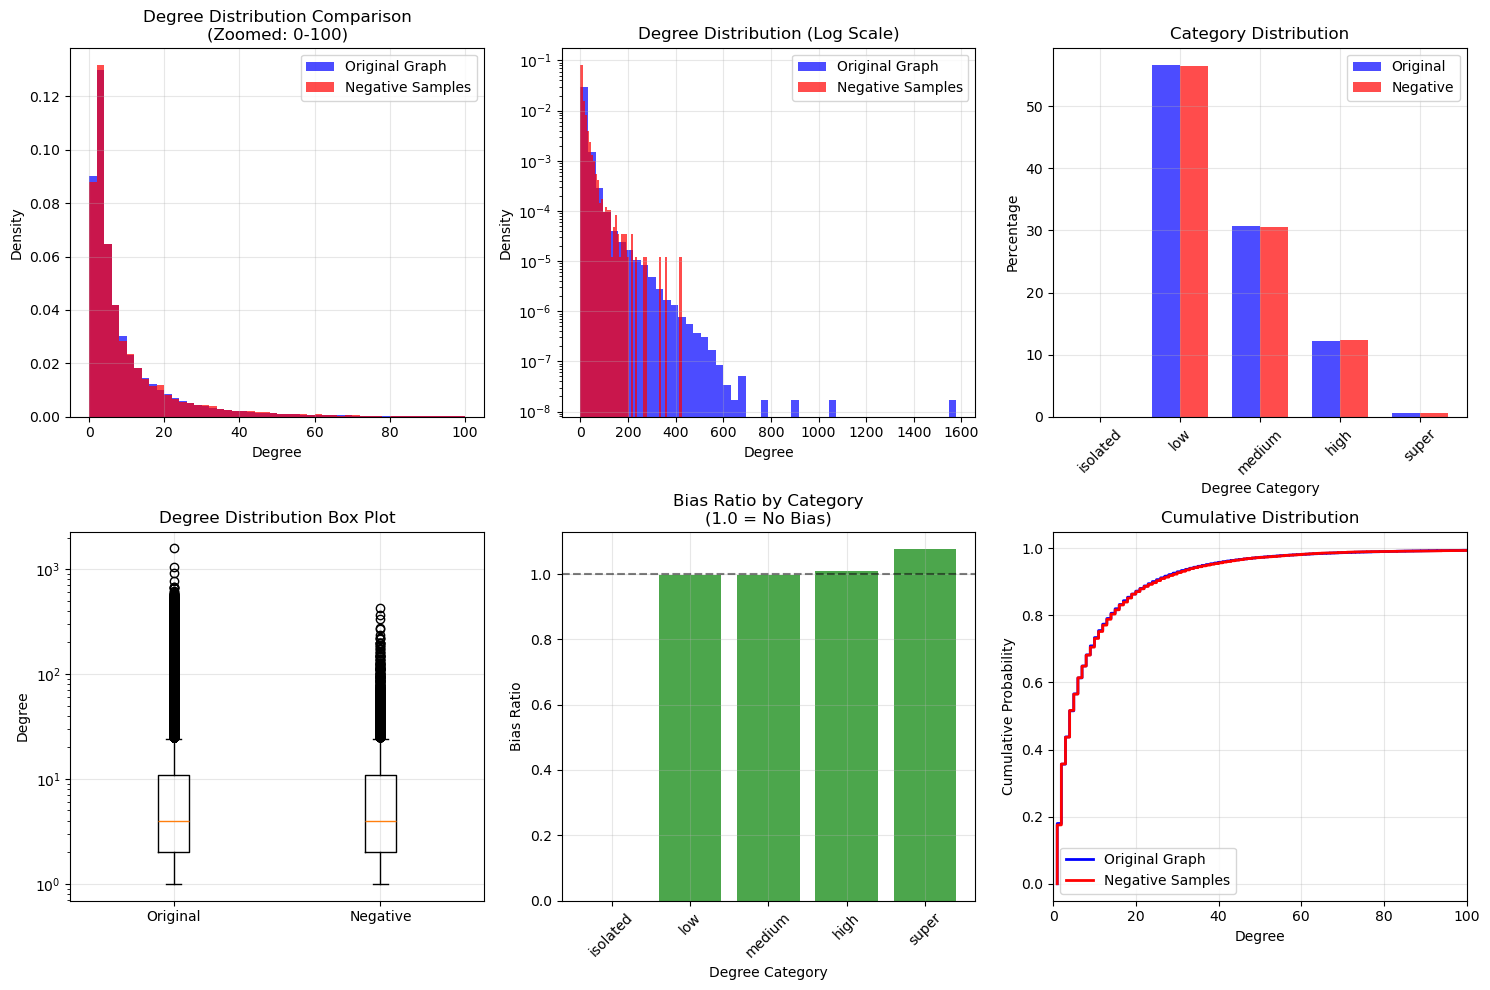


5. FINAL VERDICT AND RECOMMENDATIONS
Overall Bias Assessment: ACCEPTABLE
Bias Ratio: 1.007

✅ RECOMMENDATION: PROCEED
✅ Negative sampling appears reasonable
✅ No significant bias detected

DECISION FRAMEWORK:
🎯 YOU CAN PROCEED with current negative samples
📊 Monitor model performance and document any limitations



In [2]:
# NEGATIVE SAMPLING BIAS ANALYSIS
import pickle
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

print("=== NEGATIVE SAMPLING BIAS ANALYSIS ===")
print("Loading data and analyzing potential biases...")

# Load the original graph and negative samples
try:
    # Load original graph
    g = nx.read_edgelist('train_woheader.csv', delimiter=',', 
                        create_using=nx.DiGraph(), nodetype=int)
    
    # Load negative samples
    with open('missing_edges_final.p', 'rb') as file:
        missing_edges = pickle.load(file)
    
    print(f"✅ Original graph: {g.number_of_nodes():,} nodes, {g.number_of_edges():,} edges")
    print(f"✅ Negative samples: {len(missing_edges):,} edges")
    
except Exception as e:
    print(f"❌ Error loading data: {e}")
    exit()

# Convert negative samples to DataFrame for analysis
neg_df = pd.DataFrame(list(missing_edges), columns=['source', 'target'])
print(f"✅ Converted to DataFrame: {neg_df.shape}")

# 1. DEGREE DISTRIBUTION ANALYSIS
print(f"\n{'='*60}")
print("1. DEGREE DISTRIBUTION BIAS ANALYSIS")
print(f"{'='*60}")

# Get all nodes and their degrees from original graph
all_nodes = list(g.nodes())
node_degrees = {node: g.degree(node) for node in all_nodes}
all_degree_values = list(node_degrees.values())

print(f"Original graph degree statistics:")
print(f"• Mean degree: {np.mean(all_degree_values):.2f}")
print(f"• Median degree: {np.median(all_degree_values):.2f}")
print(f"• Std deviation: {np.std(all_degree_values):.2f}")

# Sample negative edges for analysis (using first 5000 for speed)
sample_size = min(5000, len(neg_df))
neg_sample = neg_df.sample(n=sample_size, random_state=42)

# Get degrees for negative sample nodes
neg_source_degrees = [node_degrees.get(node, 0) for node in neg_sample['source']]
neg_target_degrees = [node_degrees.get(node, 0) for node in neg_sample['target']]
neg_combined_degrees = neg_source_degrees + neg_target_degrees

print(f"\nNegative sample degree statistics (n={sample_size*2}):")
print(f"• Mean degree: {np.mean(neg_combined_degrees):.2f}")
print(f"• Median degree: {np.median(neg_combined_degrees):.2f}")
print(f"• Std deviation: {np.std(neg_combined_degrees):.2f}")

# Calculate bias ratio
bias_ratio = np.mean(neg_combined_degrees) / np.mean(all_degree_values)
print(f"\n🎯 BIAS RATIO: {bias_ratio:.3f}")

if bias_ratio > 1.2:
    print("🚩 HIGH BIAS: Negative samples favor high-degree nodes!")
    bias_verdict = "HIGH_BIAS"
elif bias_ratio > 1.1:
    print("⚠️  MODERATE BIAS: Some bias toward high-degree nodes")
    bias_verdict = "MODERATE_BIAS"
elif bias_ratio < 0.9:
    print("⚠️  REVERSE BIAS: Negative samples favor low-degree nodes")
    bias_verdict = "REVERSE_BIAS"
else:
    print("✅ ACCEPTABLE BIAS: Degree distribution looks reasonable")
    bias_verdict = "ACCEPTABLE"

# 2. CONNECTIVITY ANALYSIS
print(f"\n{'='*60}")
print("2. CONNECTIVITY PATTERN ANALYSIS")
print(f"{'='*60}")

# Check if negative samples involve nodes that exist in the graph
nodes_in_graph = set(g.nodes())
neg_sources_in_graph = sum(1 for node in neg_sample['source'] if node in nodes_in_graph)
neg_targets_in_graph = sum(1 for node in neg_sample['target'] if node in nodes_in_graph)

print(f"Negative sample connectivity:")
print(f"• Source nodes in original graph: {neg_sources_in_graph}/{sample_size} ({neg_sources_in_graph/sample_size*100:.1f}%)")
print(f"• Target nodes in original graph: {neg_targets_in_graph}/{sample_size} ({neg_targets_in_graph/sample_size*100:.1f}%)")

# 3. DEGREE CATEGORY ANALYSIS
print(f"\n{'='*60}")
print("3. DEGREE CATEGORY DISTRIBUTION")
print(f"{'='*60}")

# Define degree categories
def categorize_degree(degree):
    if degree == 0:
        return "isolated"
    elif degree <= 5:
        return "low"
    elif degree <= 20:
        return "medium"
    elif degree <= 100:
        return "high"
    else:
        return "super"

# Categorize original graph
orig_categories = [categorize_degree(d) for d in all_degree_values]
orig_category_counts = pd.Series(orig_categories).value_counts(normalize=True)

# Categorize negative samples
neg_categories = [categorize_degree(d) for d in neg_combined_degrees]
neg_category_counts = pd.Series(neg_categories).value_counts(normalize=True)

print("Degree category distribution:")
print(f"{'Category':<10} {'Original':<10} {'Negative':<10} {'Bias Ratio':<10}")
print("-" * 45)
for category in ['isolated', 'low', 'medium', 'high', 'super']:
    orig_pct = orig_category_counts.get(category, 0) * 100
    neg_pct = neg_category_counts.get(category, 0) * 100
    category_bias = (neg_pct / orig_pct) if orig_pct > 0 else 0
    print(f"{category:<10} {orig_pct:<9.1f}% {neg_pct:<9.1f}% {category_bias:<9.2f}")

# 4. VISUALIZATION
print(f"\n{'='*60}")
print("4. GENERATING BIAS VISUALIZATION")
print(f"{'='*60}")

plt.figure(figsize=(15, 10))

# Plot 1: Degree distribution comparison
plt.subplot(2, 3, 1)
plt.hist(all_degree_values, bins=50, alpha=0.7, label='Original Graph', 
         density=True, color='blue', range=(0, 100))
plt.hist(neg_combined_degrees, bins=50, alpha=0.7, label='Negative Samples', 
         density=True, color='red', range=(0, 100))
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree Distribution Comparison\n(Zoomed: 0-100)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Log scale comparison
plt.subplot(2, 3, 2)
plt.hist(all_degree_values, bins=50, alpha=0.7, label='Original Graph', 
         density=True, color='blue')
plt.hist(neg_combined_degrees, bins=50, alpha=0.7, label='Negative Samples', 
         density=True, color='red')
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree Distribution (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 3: Category comparison
plt.subplot(2, 3, 3)
categories = ['isolated', 'low', 'medium', 'high', 'super']
orig_vals = [orig_category_counts.get(cat, 0) * 100 for cat in categories]
neg_vals = [neg_category_counts.get(cat, 0) * 100 for cat in categories]

x = np.arange(len(categories))
width = 0.35
plt.bar(x - width/2, orig_vals, width, label='Original', color='blue', alpha=0.7)
plt.bar(x + width/2, neg_vals, width, label='Negative', color='red', alpha=0.7)
plt.xlabel('Degree Category')
plt.ylabel('Percentage')
plt.title('Category Distribution')
plt.xticks(x, categories, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 4: Box plot comparison
plt.subplot(2, 3, 4)
plt.boxplot([all_degree_values, neg_combined_degrees], 
           labels=['Original', 'Negative'])
plt.ylabel('Degree')
plt.title('Degree Distribution Box Plot')
plt.yscale('log')
plt.grid(True, alpha=0.3)

# Plot 5: Bias ratio by category
plt.subplot(2, 3, 5)
bias_ratios = []
for category in categories:
    orig_pct = orig_category_counts.get(category, 0)
    neg_pct = neg_category_counts.get(category, 0)
    ratio = (neg_pct / orig_pct) if orig_pct > 0 else 0
    bias_ratios.append(ratio)

colors = ['green' if 0.8 <= r <= 1.2 else 'orange' if 0.5 <= r <= 2.0 else 'red' 
          for r in bias_ratios]
plt.bar(categories, bias_ratios, color=colors, alpha=0.7)
plt.axhline(y=1.0, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Degree Category')
plt.ylabel('Bias Ratio')
plt.title('Bias Ratio by Category\n(1.0 = No Bias)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Plot 6: Cumulative distribution
plt.subplot(2, 3, 6)
orig_sorted = np.sort(all_degree_values)
neg_sorted = np.sort(neg_combined_degrees)
orig_cdf = np.arange(1, len(orig_sorted) + 1) / len(orig_sorted)
neg_cdf = np.arange(1, len(neg_sorted) + 1) / len(neg_sorted)

plt.plot(orig_sorted, orig_cdf, label='Original Graph', color='blue', linewidth=2)
plt.plot(neg_sorted, neg_cdf, label='Negative Samples', color='red', linewidth=2)
plt.xlabel('Degree')
plt.ylabel('Cumulative Probability')
plt.title('Cumulative Distribution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 100)  # Zoom to see difference better

plt.tight_layout()
plt.show()

# 5. FINAL VERDICT AND RECOMMENDATIONS
print(f"\n{'='*60}")
print("5. FINAL VERDICT AND RECOMMENDATIONS")
print(f"{'='*60}")

print(f"Overall Bias Assessment: {bias_verdict}")
print(f"Bias Ratio: {bias_ratio:.3f}")

if bias_verdict == "HIGH_BIAS":
    print("\n🚩 RECOMMENDATION: REGENERATE NEGATIVE SAMPLES")
    print("❌ Current negative sampling is significantly biased")
    print("❌ This will likely hurt model performance")
    print("✅ Suggested actions:")
    print("   1. Implement stratified negative sampling")
    print("   2. Sample proportional to degree distribution")
    print("   3. Use temporal splits if data available")
    proceed_recommendation = False
    
elif bias_verdict == "MODERATE_BIAS":
    print("\n⚠️  RECOMMENDATION: PROCEED WITH CAUTION")
    print("⚠️  Some bias detected but may be acceptable")
    print("✅ Suggested actions:")
    print("   1. Document this limitation")
    print("   2. Monitor model performance carefully")
    print("   3. Consider resampling if time permits")
    proceed_recommendation = True
    
elif bias_verdict == "REVERSE_BIAS":
    print("\n⚠️  RECOMMENDATION: INVESTIGATE FURTHER")
    print("⚠️  Unexpected bias toward low-degree nodes")
    print("✅ This might actually be beneficial for cold-start users")
    proceed_recommendation = True
    
else:
    print("\n✅ RECOMMENDATION: PROCEED")
    print("✅ Negative sampling appears reasonable")
    print("✅ No significant bias detected")
    proceed_recommendation = True

print(f"\n{'='*60}")
print("DECISION FRAMEWORK:")
print(f"{'='*60}")
if proceed_recommendation:
    print("🎯 YOU CAN PROCEED with current negative samples")
    print("📊 Monitor model performance and document any limitations")
else:
    print("🛑 CONSIDER REGENERATING negative samples")
    print("⏰ If time-constrained, proceed but add strong limitations note")

print("\n" + "="*60)